In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sympy.core.random import shuffle
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

In [2]:
# Generate the dataset
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

In [3]:
# Split the data into train, test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [4]:
# Scale the input features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
print(f"Training examples: {len(X_train_scaled)}")
print(f"Testing examples: {len(X_test_scaled)}")

Training examples: 700
Testing examples: 300


We're using the SGD optimizer with a learning rate of 0.01 for all three experiments. That optimizer applies gradient-descent updates; the batch size determines whether the gradient is calculated from one example, a mini-batch, or the whole dataset.

In [6]:
def build_model():
    model = Sequential([
        Input(shape=(2,)),
        Dense(16, activation="relu"),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01), loss="binary_crossentropy", metrics=["accuracy"])

    return model

### Batch Gradient Descent

In [7]:
# Reproducible initialization
tf.keras.utils.set_random_seed(42)

batch_model = build_model()

batch_history = batch_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=len(X_train_scaled),
    shuffle=False,
    verbose=0)

print("Batch GD Completed")

# How does this work?
# Suppose you have 700 training examples.
# 1. The network makes predictions for all 700 examples.
# 2. It calculates the loss across the dataset.
# 3. Backpropagation computes gradients based on all 700 examples.
# 4. The optimizer updates the weights and biases once.
# 5. It repeats for the next epoch.
# So, after 100 epochs, this setup makes 100 optimizer updates.
# The advantage is that each update uses information from the entire dataset, so the gradient is less noisy. The disadvantage is that each update can be computationally expensive, and you must process the whole dataset before updating the parameters.

Batch GD Completed


### Stochastic Gradient Descent

How does this work?
With 700 training examples:
1. The network processes one example.
2. It calculates the loss for that example.
3. Backpropagation calculates its gradients.
4. The optimizer updates the weights and biases.
5. It moves to another example and repeats.
That means approximately 700 updates per epoch, or 70,000 updates over 100 epochs.

In [ ]:
tf.keras.utils.set_random_seed(42)

sgd_model = build_model()

sgd_history = sgd_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=1,
    shuffle=True,
    verbose=0)

print("Stochastic Gradient Descent completed")

### Mini Batch Gradient Descent

How does this work?
With 700 training examples and a batch size of 32:
1. The network processes 32 examples.
2. It calculates their average loss and gradients.
3. The optimizer updates the weights and biases.
4. It processes the next 32 examples.
5. It continues until it has processed the training set.
There are \(700/32=22) updates per epoch, because the final batch contains the remaining examples.
Over 100 epochs, that's approximately 2,200 updates.
Mini-batches balance the two approaches: updates happen more frequently than with full-batch gradient descent, while the gradient estimates are usually less noisy than single-example SGD.

In [12]:
tf.keras.utils.set_random_seed(42)

mini_batch_model = build_model()

mini_batch_history = mini_batch_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    shuffle=True,
    verbose=0
)

print("Mini-Batch Gradient Descent completed.")

Mini-Batch Gradient Descent completed.


## Compare the results

In [13]:
results = {
    "Batch": batch_model,
    "Stochastic": sgd_model,
    "Mini-Batch": mini_batch_model}

In [15]:
for name, model in results.items():
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print(
        f"{name:12s} | "
        f"Test Loss: {loss:.4f} | "
        f"Test Accuracy: {accuracy:.2%}"
    )

Batch        | Test Loss: 0.6682 | Test Accuracy: 65.67%
Stochastic   | Test Loss: 0.7863 | Test Accuracy: 73.67%
Mini-Batch   | Test Loss: 0.2925 | Test Accuracy: 87.67%


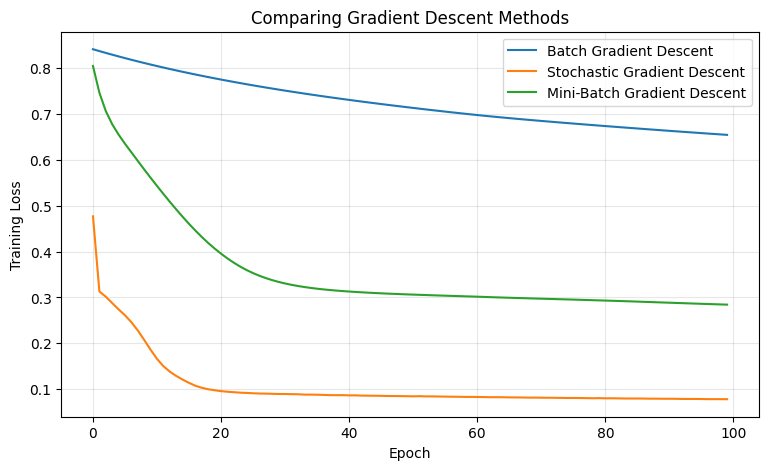

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    batch_history.history["loss"],
    label="Batch Gradient Descent"
)

plt.plot(
    sgd_history.history["loss"],
    label="Stochastic Gradient Descent"
)

plt.plot(
    mini_batch_history.history["loss"],
    label="Mini-Batch Gradient Descent"
)

# Labeling
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Comparing Gradient Descent Methods")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()